In [ ]:
# Imports
import torchvision
from torch.utils.data import Dataset

import random 
import matplotlib.pyplot as plt
from collections import defaultdict

# **1. Assembling the joint Dataset**

In [ ]:
mnist = torchvision.datasets.MNIST(root='./data', download=True, transform=None)  # Note this is only the 'training' data
svhn = torchvision.datasets.SVHN(root='./data', download=True, transform=None)    # Note this is only the 'training' data

print(len(mnist))
print(len(svhn))

60000
73257


Get the indices per label of each dataset.

In [ ]:
mnist_indices = defaultdict(list)
svhn_indices = defaultdict(list)

for i, label in enumerate(mnist.targets):
    mnist_indices[int(label)].append(i)

for i, label in enumerate(svhn.labels):
    svhn_indices[label].append(i)

print(mnist_indices[0])
print(svhn_indices[0])

[1, 21, 34, 37, 51, 56, 63, 68, 69, 75, 81, 88, 95, 108, 114, 118, 119, 121, 156, 169, 192, 206, 209, 210, 216, 229, 232, 234, 246, 249, 260, 283, 293, 296, 303, 320, 326, 359, 399, 427, 429, 435, 440, 451, 453, 458, 462, 464, 473, 489, 519, 524, 526, 527, 542, 577, 582, 596, 603, 612, 633, 639, 656, 662, 666, 667, 668, 669, 689, 702, 709, 712, 733, 743, 745, 776, 781, 787, 790, 818, 825, 849, 859, 860, 869, 872, 889, 903, 927, 943, 949, 952, 957, 965, 979, 984, 997, 1000, 1015, 1018, 1028, 1029, 1040, 1046, 1049, 1076, 1078, 1090, 1093, 1102, 1107, 1128, 1137, 1152, 1168, 1179, 1195, 1209, 1268, 1304, 1310, 1346, 1349, 1359, 1363, 1367, 1368, 1371, 1372, 1377, 1386, 1387, 1403, 1423, 1443, 1454, 1471, 1479, 1489, 1495, 1501, 1502, 1512, 1517, 1530, 1532, 1571, 1578, 1590, 1596, 1600, 1605, 1606, 1625, 1626, 1645, 1664, 1678, 1682, 1701, 1709, 1712, 1723, 1725, 1729, 1742, 1769, 1771, 1775, 1796, 1797, 1798, 1819, 1828, 1837, 1857, 1868, 1876, 1877, 1897, 1904, 1907, 1916, 1926, 1927, 

Calculating the number of pairs per number.

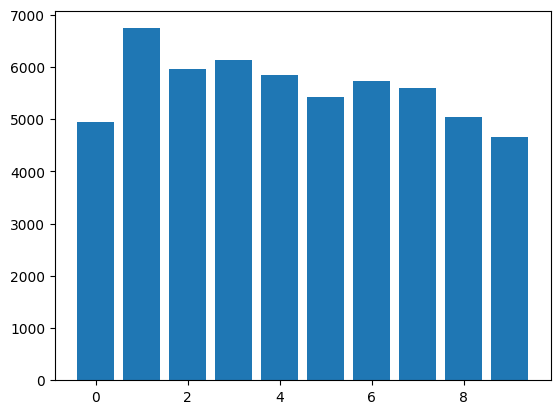

In [35]:
n_pairs = {
    digit: min(len(mnist_indices[digit]), len(svhn_indices[digit]))
    for digit in range(10)
}

plt.bar(n_pairs.keys(), n_pairs.values())
plt.show()

We decided not to balance the classes so far, since there are no big differences. Now we combine the datasets into tuples of indexes and their shared label.

In [ ]:
pairs = []

for digit in range(10):
    mnist_idx = mnist_indices[digit].copy()
    svhn_idx = svhn_indices[digit].copy()

    # Shuffle to avoid bias
    random.shuffle(mnist_idx)
    random.shuffle(svhn_idx)

    n = n_pairs[digit]

    for mnist_idx, svhn_idx in zip(mnist_idx[:n], svhn_idx[:n]):
        pairs.append((mnist_idx, svhn_idx, digit))

print(pairs)

[(27628, 49521, 0), (32273, 5481, 0), (4203, 26412, 0), (51365, 13454, 0), (21203, 44736, 0), (41729, 46211, 0), (20622, 14406, 0), (35012, 46858, 0), (19543, 34798, 0), (5692, 15765, 0), (43593, 64636, 0), (35488, 27984, 0), (3443, 33517, 0), (35632, 8949, 0), (19006, 5622, 0), (23627, 12662, 0), (24537, 4793, 0), (45418, 317, 0), (20392, 65901, 0), (51809, 34212, 0), (53685, 54479, 0), (22040, 48290, 0), (8159, 71813, 0), (47005, 69495, 0), (31020, 13031, 0), (38335, 3727, 0), (48607, 35567, 0), (43915, 23834, 0), (40188, 38158, 0), (39075, 23137, 0), (15382, 27852, 0), (27900, 56772, 0), (13411, 26994, 0), (56914, 54773, 0), (41999, 60374, 0), (22245, 51982, 0), (49331, 4843, 0), (22270, 58101, 0), (5801, 53690, 0), (56137, 10025, 0), (21142, 13224, 0), (41606, 2822, 0), (27749, 39741, 0), (38543, 23886, 0), (39581, 16580, 0), (5120, 66854, 0), (9439, 26096, 0), (46751, 51173, 0), (32785, 11407, 0), (20256, 63103, 0), (51422, 44009, 0), (46069, 16916, 0), (28427, 18558, 0), (4539, 7

Now we create a combained pytorch dataset with both images and their label.

In [ ]:
class CombinedDataset(Dataset):
    def __init__(self, mnist, svhn, pairs):
        self.mnist = mnist
        self.svhn = svhn
        self.pairs = pairs

    def __len__(self):
        return len(self.pairs)

    def __getitem__(self, idx):
        mnist_idx, svhn_idx, label = self.pairs[idx]

        img_mnist, _ = self.mnist[mnist_idx]
        img_svhn, _ = self.svhn[svhn_idx]

        return img_mnist, img_svhn, label

Label: 0


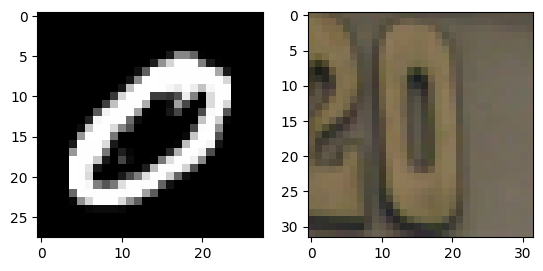

In [ ]:
combined = CombinedDataset(mnist, svhn, pairs)

img_mnist, img_svhn, label = combined[1]
print('Label:', label)
plt.subplot(1, 2, 1)
plt.imshow(img_mnist, cmap = 'gray')
plt.subplot(1, 2, 2)
plt.imshow(img_svhn)
plt.show()